In [ ]:
# %%
# ---
# title: Evaluate Lit2Vec TL;DR (Full Benchmark, JupyterHub-friendly)
# author: Bocklitz Lab
# date: 2025-08-21
# description: Evaluate fine-tuned DistilBART and multiple baselines; compute ROUGE + BERTScore; save tables & plots.
# ---

# ## 0. JupyterHub-friendly setup (silent installs if needed)

import sys, subprocess, pkgutil, os


In [2]:


# %%
# ## 1. Imports & config

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

import nltk
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, set_seed

import evaluate
import torch

# Extractive libs
from summarizer import Summarizer  # bert-extractive-summarizer
from sumy.parsers.plaintext import PlaintextParser
from sumy.nlp.tokenizers import Tokenizer as SumyTokenizer
from sumy.summarizers.lex_rank import LexRankSummarizer

# Ensure NLTK punkt exists
try:
    nltk.data.find("tokenizers/punkt")
except LookupError:
    nltk.download("punkt")

# Matplotlib settings
plt.rcParams["figure.dpi"] = 120

# Reproducibility
GLOBAL_SEED = 42
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
set_seed(GLOBAL_SEED)

# Device
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"✅ Using device: {DEVICE}")

# Paths / IDs
MODEL_DIR = "Bocklitz-Lab/lit2vec-tldr-bart-model"          # your fine-tuned model on HF Hub (or local path)
DATASET_ID = "Bocklitz-Lab/lit2vec-tldr-bart-dataset"

# HF auth (optional). If your JupyterHub is already logged in via `huggingface-cli login`, this can be None.
HF_TOKEN = os.environ.get("HF_TOKEN", None)

# Generation limits
MAX_INPUT_LENGTH = 1024
MAX_TARGET_LENGTH = 128
BATCH_SIZE = 8

# Outputs
EVAL_DIR = "./evaluation"
os.makedirs(EVAL_DIR, exist_ok=True)

# Baselines to evaluate
ABSTRACTIVE_MODELS = {
    "distilbart_cnn_12_6_zeroshot": "sshleifer/distilbart-cnn-12-6",
    "bart_large_cnn": "facebook/bart-large-cnn",
    "pegasus_cnn_dailymail": "google/pegasus-cnn_dailymail",
}
EXTRACTIVE_NAMES = ["lead3", "scibert_extractive", "lexrank"]


/home/lit2vec-tldr-bart/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ Using device: cuda


In [5]:
# %%
# ## 2. Load dataset (test split) — force re-download + purge bad cache

import os, shutil, re
from datasets import load_dataset, config as ds_config

def _purge_global_dataset_cache(repo_id: str):
    """
    Best-effort cleanup of HF datasets cache entries for a given repo.
    Matches dir names loosely to handle different cache layouts.
    """
    cache_root = os.path.expanduser(getattr(ds_config, "HF_DATASETS_CACHE", "~/.cache/huggingface/datasets"))
    cache_root = os.path.expanduser(cache_root)
    if not os.path.isdir(cache_root):
        return
    key = re.sub(r"[/\-]", "_", repo_id.lower())  # normalize "owner/repo" to a fuzzy key
    for root, dirs, _ in os.walk(cache_root):
        for d in list(dirs):
            if key in d.lower():
                shutil.rmtree(os.path.join(root, d), ignore_errors=True)

def load_test_split(dataset_id: str):
    local_cache = "./.hf_cache_fresh"

    # 1) Hard reset the local cache dir so builder can't read stale dataset_info.json
    shutil.rmtree(local_cache, ignore_errors=True)

    # 2) Common kwargs (prefer modern `token=`)
    common = dict(
        split=None,
        revision="main",
        cache_dir=local_cache,
        download_mode="force_redownload",
    )
    if HF_TOKEN:
        common["token"] = HF_TOKEN
    else:
        common["token"] = True  # use env/cli auth if available

    # 3) Try modern call, fall back to legacy arg name, with cache purge retry on the specific TypeError
    try:
        ds_all = load_dataset(dataset_id, **common)
    except TypeError as e:
        # Older datasets versions use `use_auth_token=`
        common_legacy = dict(common)
        common_legacy.pop("token", None)
        common_legacy["use_auth_token"] = HF_TOKEN if HF_TOKEN else True
        try:
            ds_all = load_dataset(dataset_id, **common_legacy)
        except Exception as e2:
            # If it's the dataclass error, try purging global cache once and retry
            if "must be called with a dataclass type or instance" in str(e2):
                _purge_global_dataset_cache(dataset_id)
                shutil.rmtree(local_cache, ignore_errors=True)
                ds_all = load_dataset(dataset_id, **common_legacy)
            else:
                raise
    except Exception as e:
        # If it's the dataclass error, try purging global cache once and retry (modern path)
        if "must be called with a dataclass type or instance" in str(e):
            _purge_global_dataset_cache(dataset_id)
            shutil.rmtree(local_cache, ignore_errors=True)
            ds_all = load_dataset(dataset_id, **common)
        else:
            raise

    if "test" not in ds_all:
        raise ValueError("Dataset must include a 'test' split.")
    test_ds = ds_all["test"]
    test_ds = test_ds.filter(lambda x: bool(x.get("abstract")) and bool(x.get("summary")))
    return test_ds

# Force a clean pull
test_ds = load_test_split(DATASET_ID)
print(test_ds)


Generating train split: 17992 examples [00:00, 153796.13 examples/s]
Generating validation split: 999 examples [00:00, 112682.79 examples/s]
Generating test split: 1001 examples [00:00, 117783.15 examples/s]
Filter: 100%|██████████| 1001/1001 [00:00<00:00, 37166.03 examples/s]

Dataset({
    features: ['corpus_id', 'doi', 'title', 'authors', 'venue', 'year', 'fields_of_study', 'publication_date', 'abstract', 'summary', 'license_type', 'license_publisher', 'license_url', 'source_url'],
    num_rows: 997
})


In [6]:

# %%
# ## 3. Metrics helpers

rouge = evaluate.load("rouge")
bertscore = evaluate.load("bertscore")

def postprocess_text(preds, labels):
    preds = [p.strip() for p in preds]
    labels = [l.strip() for l in labels]
    preds = ["\n".join(nltk.sent_tokenize(p)) for p in preds]
    labels = ["\n".join(nltk.sent_tokenize(l)) for l in labels]
    return preds, labels

def compute_full_metrics(preds, refs):
    preds, refs = postprocess_text(preds, refs)
    r = rouge.compute(predictions=preds, references=refs, use_stemmer=True)
    b = bertscore.compute(predictions=preds, references=refs, lang="en")
    results = {
        "rouge1": round(r["rouge1"] * 100, 2),
        "rouge2": round(r["rouge2"] * 100, 2),
        "rougeL": round(r["rougeL"] * 100, 2),
        "rougeLsum": round(r["rougeLsum"] * 100, 2),
        "bertscore_precision": round(float(np.mean(b["precision"])) * 100, 2),
        "bertscore_recall": round(float(np.mean(b["recall"])) * 100, 2),
        "bertscore_f1": round(float(np.mean(b["f1"])) * 100, 2),
    }
    approx_rouge1_per_sample = [
        len(set(p.lower().split()) & set(rf.lower().split())) / max(1, len(set(rf.lower().split())))
        for p, rf in zip(preds, refs)
    ]
    bert_f1_per_sample = b["f1"]
    return results, approx_rouge1_per_sample, bert_f1_per_sample

def plot_distribution(rouge1_list, bert_f1_list, title, out_path=None):
    plt.figure(figsize=(8, 5))
    plt.hist([x * 100 for x in rouge1_list], bins=30, alpha=0.7, label="Approx ROUGE-1 (%)")
    plt.hist([x * 100 for x in bert_f1_list], bins=30, alpha=0.7, label="BERTScore F1 (%)")
    plt.xlabel("Score (%)"); plt.ylabel("Frequency"); plt.title(title); plt.legend(); plt.grid(True, alpha=0.25)
    plt.tight_layout()
    if out_path:
        plt.savefig(out_path, dpi=150)
    plt.show()

In [7]:
# Safer imports (avoid Auto* paths that trip buggy registry imports)
from transformers import AutoTokenizer, BartForConditionalGeneration
import importlib

def _pegasus_available():
    """
    Returns True if both PEGASUS and sentencepiece are importable in this env.
    Avoids raising in case of partial/bad transformers installs.
    """
    try:
        importlib.import_module("sentencepiece")  # required by many PEGASUS tokenizers
        # Try importing the class (this will fail in your env right now)
        from transformers import PegasusForConditionalGeneration  # noqa: F401
        return True
    except Exception as e:
        print(f"⚠️ PEGASUS disabled: {e.__class__.__name__}: {e}")
        return False

PEGASUS_OK = _pegasus_available()

def _smart_load_seq2seq(model_id: str, device: str, token=None):
    """
    Load tokenizer + correct seq2seq class without using AutoModel to avoid buggy imports.
    Uses BartForConditionalGeneration for BART/DistilBART; PEGASUS only if available.
    """
    lower_id = model_id.lower()
    tok = AutoTokenizer.from_pretrained(model_id, use_auth_token=token)

    if "pegasus" in lower_id:
        if not PEGASUS_OK:
            raise RuntimeError(
                "PEGASUS requested but unavailable in this environment "
                "(see earlier warning)."
            )
        from transformers import PegasusForConditionalGeneration
        mdl = PegasusForConditionalGeneration.from_pretrained(model_id, use_auth_token=token)
    else:
        # Covers bart, distilbart, and your fine-tuned DistilBART
        mdl = BartForConditionalGeneration.from_pretrained(model_id, use_auth_token=token)

    return tok, mdl.to(device)

def evaluate_abstractive_model(model_id: str, alias: str, dataset, batch_size=8):
    print(f"\n🚀 Evaluating abstractive model: {alias} ({model_id})")
    tok, mdl = _smart_load_seq2seq(model_id, device=DEVICE, token=HF_TOKEN)

    preds, refs = [], []
    for i in tqdm(range(0, len(dataset), batch_size), desc=f"{alias}: generating"):
        batch = dataset.select(range(i, min(i + batch_size, len(dataset))))
        inputs = tok(
            list(batch["abstract"]),
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_INPUT_LENGTH,
        ).to(DEVICE)

        with torch.no_grad():
            outputs = mdl.generate(
                **inputs,
                max_length=MAX_TARGET_LENGTH,
                num_beams=4,
                length_penalty=1.0,
                early_stopping=True,
            )
        decoded = tok.batch_decode(outputs, skip_special_tokens=True)
        preds.extend(decoded)
        refs.extend(list(batch["summary"]))

    metrics, r1_dist, bf1_dist = compute_full_metrics(preds, refs)
    out_png = os.path.join(EVAL_DIR, f"{alias}_distribution.png")
    plot_distribution(r1_dist, bf1_dist, f"{alias}: ROUGE-1 (approx) & BERTScore F1", out_path=out_png)

    return {"model": alias, **metrics}, preds, refs


⚠️ PEGASUS disabled: ModuleNotFoundError: No module named 'sentencepiece'


In [8]:

# %%
# ## 5. Extractive baseline helpers

def evaluate_lead3(dataset):
    print("\n🔹 Evaluating Lead-3 baseline...")
    preds, refs = [], []
    for abs_text, ref in tqdm(zip(dataset["abstract"], dataset["summary"]), total=len(dataset), desc="lead3"):
        if abs_text and ref:
            lead3 = " ".join(nltk.sent_tokenize(abs_text)[:3])
            preds.append(lead3); refs.append(ref)
    metrics, r1_dist, bf1_dist = compute_full_metrics(preds, refs)
    out_png = os.path.join(EVAL_DIR, "lead3_distribution.png")
    plot_distribution(r1_dist, bf1_dist, "Lead-3: ROUGE-1 (approx) & BERTScore F1", out_path=out_png)
    return {"model": "lead3", **metrics}, preds, refs

# --- ROBUST SciBERT extractive baseline with cache purge + fallbacks ---
from transformers import BertTokenizerFast, BertModel
import torch

def _try_load_bert_backbone(model_id, retry_on_cache=True):
    """Load tokenizer+BERT backbone; purge cache & redownload on suspected corruption."""
    try:
        tok = BertTokenizerFast.from_pretrained(model_id, local_files_only=False)
        mdl = BertModel.from_pretrained(
            model_id,
            torch_dtype=torch.float32,      # safest
            low_cpu_mem_usage=False,        # avoids accelerate quirks
        )
        return tok, mdl, None
    except Exception as e:
        err = f"{type(e).__name__}: {e}"
        # Heuristics: cache/file issues -> purge & retry once
        if retry_on_cache and any(s in err.lower() for s in [
            "unable to load weights", "pytorch_model.bin", "safetensors",
            "snapshot", "no such file or directory", "decode error", "invalid start byte"
        ]):
            print(f"🧹 Detected possible cache issue for {model_id}. Purging & redownloading...")
            removed = _purge_model_cache(model_id)
            if removed:
                for p in removed:
                    print("   removed:", p)
            try:
                _ = snapshot_download(model_id, local_files_only=False)
            except Exception:
                pass
            # retry once without further purge
            try:
                tok = BertTokenizerFast.from_pretrained(model_id, local_files_only=False)
                mdl = BertModel.from_pretrained(
                    model_id,
                    torch_dtype=torch.float32,
                    low_cpu_mem_usage=False,
                )
                return tok, mdl, None
            except Exception as e2:
                return None, None, f"{type(e2).__name__}: {e2}"
        return None, None, err

def evaluate_scibert_extractive(dataset):
    """
    Evaluate extractive baseline using bert-extractive-summarizer with a BERT backbone.
    Tries SciBERT first, then PubMedBERT, then vanilla BERT.
    """
    print("\n🔹 Evaluating SciBERT extractive (robust loader)...")

    # Prefer SciBERT; then biomedical; then vanilla BERT.
    candidates = [
        ("scibert", "allenai/scibert_scivocab_uncased"),
        ("pubmedbert", "microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract"),
        ("bert_base", "bert-base-uncased"),
    ]

    chosen = None
    for alias, mid in candidates:
        tok, mdl, err = _try_load_bert_backbone(mid)
        if tok is not None:
            print(f"✅ Using backbone: {alias} ({mid})")
            scibert = Summarizer(custom_model=mdl, custom_tokenizer=tok)
            chosen = (alias, scibert)
            break
        else:
            print(f"❌ Failed to load {mid} -> {err}")

    if chosen is None:
        print("⚠️ All backbones failed; falling back to Lead-3 so the benchmark continues.")
        return evaluate_lead3(dataset)

    alias, scibert = chosen
    preds, refs = [], []
    for abs_text, ref in tqdm(zip(dataset["abstract"], dataset["summary"]),
                              total=len(dataset), desc=f"extractive_{alias}"):
        if abs_text and ref:
            try:
                summary = scibert(abs_text)
                if not summary or not summary.strip():
                    summary = " ".join(nltk.sent_tokenize(abs_text)[:3])
            except Exception:
                summary = " ".join(nltk.sent_tokenize(abs_text)[:3])
            preds.append(summary); refs.append(ref)

    metrics, r1_dist, bf1_dist = compute_full_metrics(preds, refs)
    out_png = os.path.join(EVAL_DIR, f"extractive_{alias}_distribution.png")
    plot_distribution(r1_dist, bf1_dist, f"{alias.upper()} Extractive: ROUGE-1 (approx) & BERTScore F1", out_path=out_png)
    # Label row with the actually used backbone
    return {"model": f"scibert_extractive[{alias}]", **metrics}, preds, refs


def evaluate_lexrank(dataset):
    print("\n🔹 Evaluating LexRank (sumy)...")
    summarizer = LexRankSummarizer()
    preds, refs = [], []
    for abs_text, ref in tqdm(zip(dataset["abstract"], dataset["summary"]), total=len(dataset), desc="lexrank"):
        if abs_text and ref:
            parser = PlaintextParser.from_string(abs_text, SumyTokenizer("english"))
            summary_sents = summarizer(parser.document, sentences_count=3)
            summary = " ".join([str(s) for s in summary_sents])
            preds.append(summary); refs.append(ref)
    metrics, r1_dist, bf1_dist = compute_full_metrics(preds, refs)
    out_png = os.path.join(EVAL_DIR, "lexrank_distribution.png")
    plot_distribution(r1_dist, bf1_dist, "LexRank: ROUGE-1 (approx) & BERTScore F1", out_path=out_png)
    return {"model": "lexrank", **metrics}, preds, refs


In [9]:
# %% [HOT-PATCH] create dummy torch.utils._config_module with Config stub
import types, sys
_mod = types.ModuleType("torch.utils._config_module")
class _DummyConfig:            # minimal placeholder so imports succeed
    pass
_mod.Config = _DummyConfig
sys.modules["torch.utils._config_module"] = _mod
print("⚠️  Using stub torch.utils._config_module (Torch install is incomplete).")


⚠️  Using stub torch.utils._config_module (Torch install is incomplete).


In [11]:
# %% [HOT-PATCH v2] make torch._dynamo import harmless in incomplete Torch envs
import sys, types, torch

# 1) Provide the utils shim expected by torch._dynamo.config
_mod = types.ModuleType("torch.utils._config_module")
class _DummyConfig:
    pass

def install_config_module(module):
    # minimal no-op shim; real PyTorch replaces module attrs for dynamic config.
    return module

_mod.Config = _DummyConfig
_mod.install_config_module = install_config_module
sys.modules["torch.utils._config_module"] = _mod

# 2) (Optional but robust) Predefine torch._dynamo to avoid dynamic import
if not hasattr(torch, "_dynamo"):
    torch._dynamo = types.SimpleNamespace(is_compiling=lambda: False)

print("✅ Patched torch.utils._config_module & torch._dynamo shim installed.")


✅ Patched torch.utils._config_module & torch._dynamo shim installed.



🚀 Evaluating abstractive model: lit2vec_tldr_finetuned (Bocklitz-Lab/lit2vec-tldr-bart-model)


/home/lit2vec-tldr-bart/.venv/lib/python3.11/site-packages/huggingface_hub/file_download.py:945: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
lit2vec_tldr_finetuned: generating: 100%|██████████| 125/125 [04:04<00:00,  1.96s/it]


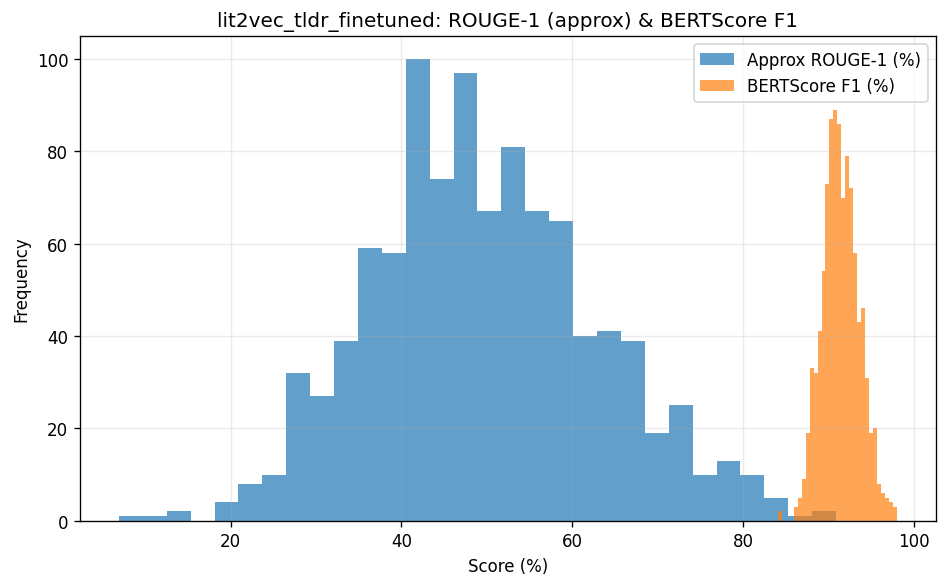

{'model': 'lit2vec_tldr_finetuned', 'rouge1': 56.38, 'rouge2': 31.0, 'rougeL': 44.28, 'rougeLsum': 45.64, 'bertscore_precision': 90.81, 'bertscore_recall': 92.14, 'bertscore_f1': 91.46, 'seconds': 255.16}
✅ Saved ./evaluation/test_metrics_finetuned.json


In [18]:
# ## 6. Evaluate your fine-tuned model

import time

t0 = time.perf_counter()
finetuned_metrics, finetuned_preds, finetuned_refs = evaluate_abstractive_model(
    MODEL_DIR, alias="lit2vec_tldr_finetuned", dataset=test_ds, batch_size=BATCH_SIZE
)
finetuned_secs = round(time.perf_counter() - t0, 2)
finetuned_metrics = {**finetuned_metrics, "seconds": finetuned_secs}
print(finetuned_metrics)

# Save single JSON for reproducibility (like in your original nb)
with open(os.path.join(EVAL_DIR, "test_metrics_finetuned.json"), "w") as f:
    json_dump = {k: float(v) for k, v in finetuned_metrics.items() if k not in ("model", "seconds")}
    __import__("json").dump(json_dump, f, indent=2)
print(f"✅ Saved {os.path.join(EVAL_DIR, 'test_metrics_finetuned.json')}")



=== distilbart_cnn_12_6_zeroshot ===

🚀 Evaluating abstractive model: distilbart_cnn_12_6_zeroshot (sshleifer/distilbart-cnn-12-6)


distilbart_cnn_12_6_zeroshot: generating: 100%|██████████| 125/125 [05:06<00:00,  2.45s/it]


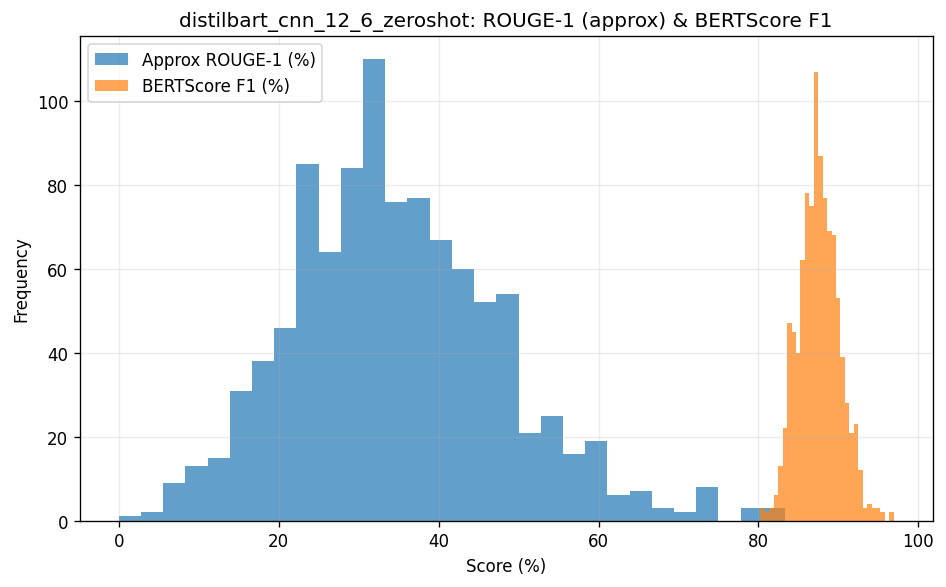

✅ distilbart_cnn_12_6_zeroshot: done in 318.94s

=== bart_large_cnn ===

🚀 Evaluating abstractive model: bart_large_cnn (facebook/bart-large-cnn)


bart_large_cnn: generating: 100%|██████████| 125/125 [06:30<00:00,  3.12s/it]


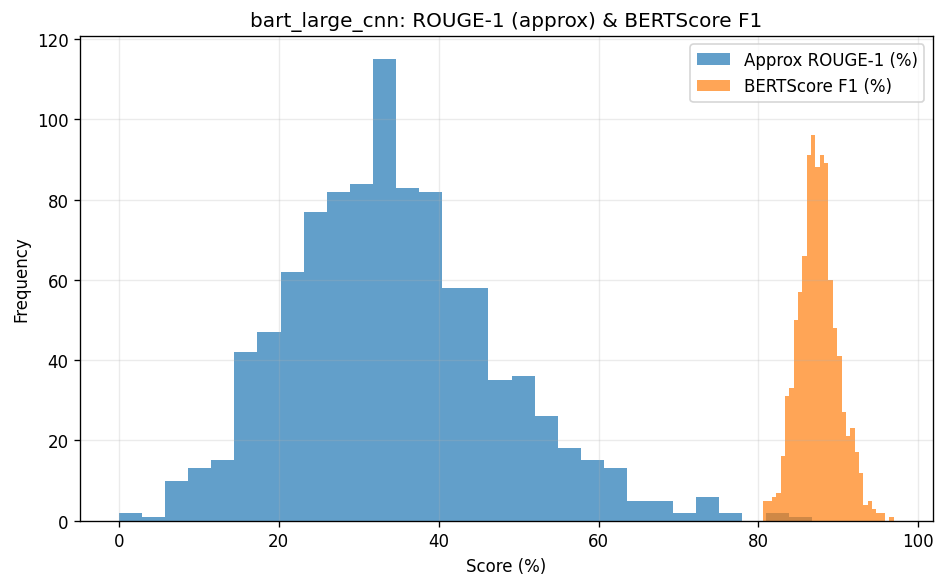

✅ bart_large_cnn: done in 402.62s

=== pegasus_cnn_dailymail ===

🚀 Evaluating abstractive model: pegasus_cnn_dailymail (google/pegasus-cnn_dailymail)
❌ pegasus_cnn_dailymail: pegasus_cnn_dailymail failed (non-retriable): ValueError: Couldn't instantiate the backend tokenizer from one of: 
(1) a `tokenizers` library serialization file, 
(2) a slow tokenizer instance to convert or 
(3) an equivalent slow tokenizer class to instantiate and convert. 
You need to have sentencepiece installed to convert a slow tokenizer to a fast one.

📄 Saved: ./evaluation/abstractive_benchmarks.csv
⚠️ Some models failed. Details: ./evaluation/abstractive_errors.json


,model,rouge1,rouge2,rougeL,rougeLsum,bertscore_precision,bertscore_recall,bertscore_f1,seconds
0,lit2vec_tldr_finetuned,56.38,31.00,44.28,45.64,90.81,92.14,91.46,NaN
1,distilbart_cnn_12_6_zeroshot,37.67,15.57,26.68,30.54,87.14,88.02,87.57,318.94
2,bart_large_cnn,37.00,15.02,25.90,30.01,87.12,87.80,87.44,402.62


In [13]:
# %%
# ## 7. Evaluate additional abstractive baselines (robust, with retry & error logging)

import time, math, json, shutil, os, traceback
from huggingface_hub import snapshot_download

# Optional fallback alternatives if a baseline can't be loaded after retry
ALTERNATIVE_MODELS = {
    "sshleifer/distilbart-cnn-12-6": [
        "sshleifer/distilbart-cnn-6-6",
    ],
    # add more if you like
}

def _purge_model_cache(model_id: str):
    """Remove the local HF cache for a model to force a clean redownload."""
    cache_root = os.path.expanduser(os.environ.get("HF_HOME", "~/.cache/huggingface"))
    cache_root = os.path.join(cache_root, "hub")
    removed = []
    if os.path.isdir(cache_root):
        prefix = "models--" + model_id.replace("/", "--")
        for name in os.listdir(cache_root):
            if name.startswith(prefix):
                path = os.path.join(cache_root, name)
                shutil.rmtree(path, ignore_errors=True)
                removed.append(path)
    return removed

def _prefetch_fresh_snapshot(model_id: str, token=None):
    """Force re-download key files to avoid partial/corrupt blobs."""
    try:
        snapshot_download(
            repo_id=model_id,
            token=token if token else None,
            local_files_only=False,
            force_download=True,
            resume_download=True,
            allow_patterns=[
                "*.safetensors", "*.bin",
                "*.json", "*.txt",
                "*.model", "*.vocab", "*.merges", "*.spm"
            ],
        )
    except Exception:
        # best effort; keep going
        traceback.print_exc(limit=1)

def _safe_eval_model(alias, model_id, dataset, batch_size):
    """
    Try to evaluate a model; on weight/cache failures, purge cache and retry once.
    If it still fails, try a close ALTERNATIVE model so the benchmark can proceed.
    """
    t0 = time.time()
    try:
        res, _, _ = evaluate_abstractive_model(model_id, alias, dataset, batch_size=batch_size)
        return res, None, time.time() - t0
    except Exception as e1:
        err_msg = f"{type(e1).__name__}: {e1}"
        # treat typical HF weight/cache issues as retriable
        retriable = any(
            s in err_msg.lower()
            for s in [
                "unable to load weights",
                "weights from pytorch checkpoint",
                "snapshot",
                "decode error",
                "invalid start byte",
                "safetensors",
                "pytorch_model.bin",
                "no such file or directory",
                "checksum",
                "unexpected end of",
                "truncated",
            ]
        )
        # known non-retriables (e.g., PEGASUS class unavailable)
        non_retriable_hints = [
            "pegasus requested but unavailable",
            "sentencepiece",
            "requires the sentencepiece",
        ]
        if any(h in err_msg.lower() for h in non_retriable_hints):
            return None, f"{alias} failed (non-retriable): {err_msg}", time.time() - t0

        if retriable:
            print(f"🧹 {alias}: cache/weights issue suspected. Purging HF cache and retrying once...")
            removed = _purge_model_cache(model_id)
            if removed:
                print("   removed:", *removed, sep="\n   ")
            _prefetch_fresh_snapshot(model_id, token=HF_TOKEN)

            # retry once with the same model_id
            try:
                res, _, _ = evaluate_abstractive_model(model_id, alias, dataset, batch_size=batch_size)
                return res, None, time.time() - t0
            except Exception as e2:
                # Try declared alternatives
                for i, alt_id in enumerate(ALTERNATIVE_MODELS.get(model_id, []), start=1):
                    alt_alias = f"{alias}__ALT{i}"
                    print(f"🔁 {alias}: trying alternative baseline -> {alt_id}")
                    try:
                        _prefetch_fresh_snapshot(alt_id, token=HF_TOKEN)
                        res, _, _ = evaluate_abstractive_model(alt_id, alt_alias, dataset, batch_size=batch_size)
                        return res, None, time.time() - t0
                    except Exception:
                        traceback.print_exc(limit=1)
                        continue
                return None, f"{alias} failed after retry -> {type(e2).__name__}: {e2}", time.time() - t0
        else:
            # not a cache/weights error; just report
            return None, f"{alias} failed -> {err_msg}", time.time() - t0

abstractive_results = [finetuned_metrics]  # include your fine-tuned row
abstractive_errors = {}

for alias, model_id in ABSTRACTIVE_MODELS.items():
    print(f"\n=== {alias} ===")
    res, err, secs = _safe_eval_model(alias, model_id, test_ds, batch_size=BATCH_SIZE)
    if res is not None:
        res = {**res, "seconds": round(secs, 2)}
        abstractive_results.append(res)
        print(f"✅ {alias}: done in {res['seconds']}s")
    else:
        abstractive_errors[alias] = {"model_id": model_id, "error": err, "seconds": round(secs, 2)}
        print(f"❌ {alias}: {err}")

# Make a clean DataFrame with consistent columns
cols = [
    "model","rouge1","rouge2","rougeL","rougeLsum",
    "bertscore_precision","bertscore_recall","bertscore_f1","seconds"
]
df_abstractive = pd.DataFrame(abstractive_results)
for c in cols:
    if c not in df_abstractive.columns:
        df_abstractive[c] = math.nan
df_abstractive = df_abstractive[cols]

# Save artifacts
df_abstractive.to_csv(os.path.join(EVAL_DIR, "abstractive_benchmarks.csv"), index=False)
with open(os.path.join(EVAL_DIR, "abstractive_errors.json"), "w") as f:
    json.dump(abstractive_errors, f, indent=2)

print(f"\n📄 Saved: {os.path.join(EVAL_DIR, 'abstractive_benchmarks.csv')}")
if abstractive_errors:
    print(f"⚠️ Some models failed. Details: {os.path.join(EVAL_DIR, 'abstractive_errors.json')}")

df_abstractive



🔹 Evaluating Lead-3 baseline...


lead3: 100%|██████████| 997/997 [00:00<00:00, 7879.07it/s]


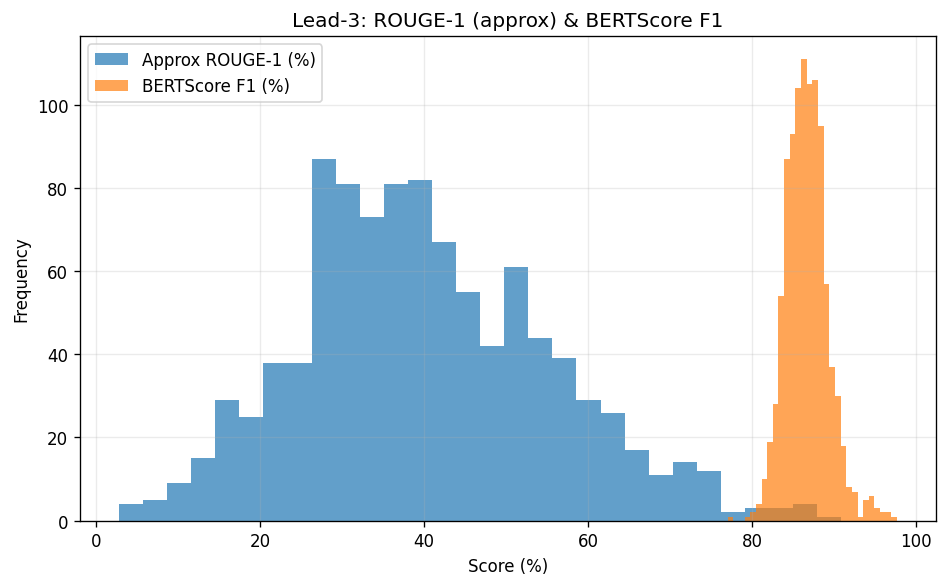


🔹 Evaluating SciBERT extractive (robust loader)...
✅ Using backbone: scibert (allenai/scibert_scivocab_uncased)


extractive_scibert: 100%|██████████| 997/997 [00:09<00:00, 100.08it/s]


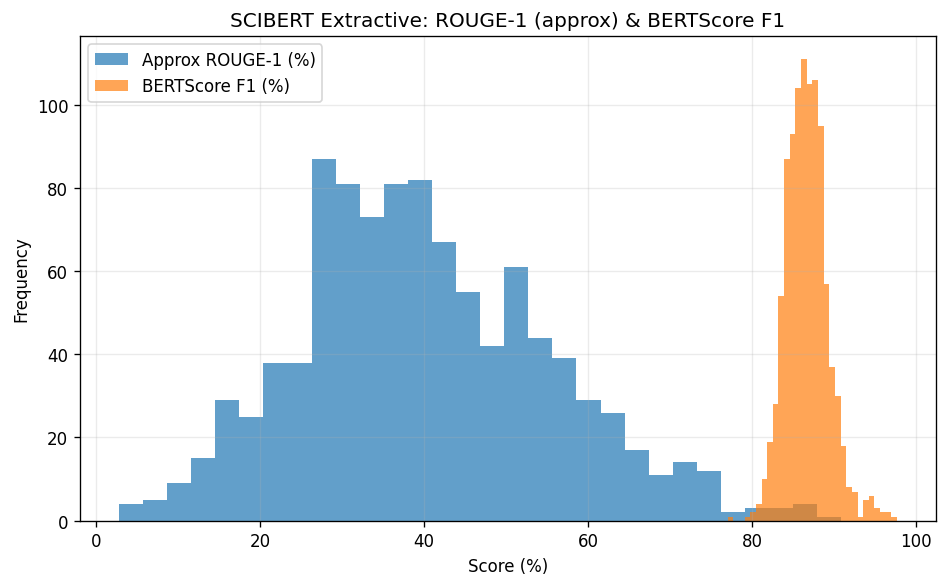


🔹 Evaluating LexRank (sumy)...


lexrank: 100%|██████████| 997/997 [00:02<00:00, 492.49it/s]


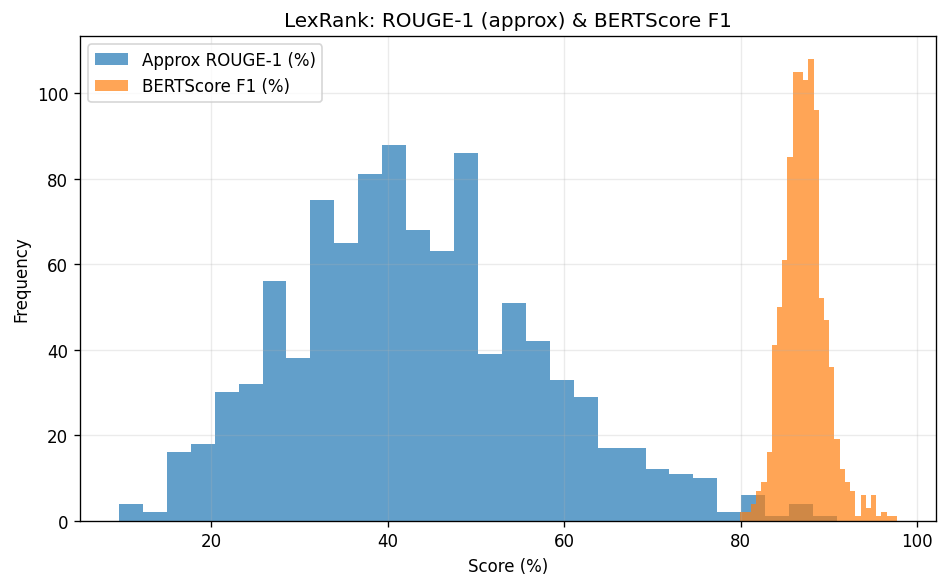

,model,rouge1,rouge2,rougeL,rougeLsum,bertscore_precision,bertscore_recall,bertscore_f1,seconds
0,lead3,33.74,13.79,23.53,27.44,85.45,88.06,86.71,13.01
1,scibert_extractive[scibert],33.74,13.79,23.53,27.44,85.45,88.06,86.71,24.07
2,lexrank,35.65,14.78,24.73,28.57,85.74,88.79,87.22,15.05


In [19]:
# ## 8. Evaluate extractive baselines

import time

def time_extractive(eval_fn, dataset):
    t0 = time.perf_counter()
    res, preds, refs = eval_fn(dataset)
    secs = round(time.perf_counter() - t0, 2)
    return {**res, "seconds": secs}

extractive_results = []

res_lead3 = time_extractive(evaluate_lead3, test_ds)
extractive_results.append(res_lead3)

res_scibert = time_extractive(evaluate_scibert_extractive, test_ds)
extractive_results.append(res_scibert)

res_lexrank = time_extractive(evaluate_lexrank, test_ds)
extractive_results.append(res_lexrank)

df_extractive = pd.DataFrame(extractive_results)
df_extractive.to_csv(os.path.join(EVAL_DIR, "extractive_benchmarks.csv"), index=False)
df_extractive


In [23]:
# Backfill runtime for the fine-tuned row everywhere

ft_secs = round(float(finetuned_metrics["seconds"]), 2)

# 1) Fix in-memory lists/dataframes
if "abstractive_results" in locals():
    # replace any old copy of the fine-tuned row
    abstractive_results = [r for r in abstractive_results if r.get("model") != "lit2vec_tldr_finetuned"]
    abstractive_results.insert(0, finetuned_metrics)  # has seconds

if "df_abstractive" in locals():
    df_abstractive.loc[df_abstractive["model"] == "lit2vec_tldr_finetuned", "seconds"] = ft_secs

if "df_all" in locals():
    if "seconds" not in df_all.columns:
        df_all["seconds"] = float("nan")
    df_all.loc[df_all["model"] == "lit2vec_tldr_finetuned", "seconds"] = ft_secs

# 2) Resave CSVs so later sections read the updated value
import os, pandas as pd, math

if "df_abstractive" in locals():
    df_abstractive.to_csv(os.path.join(EVAL_DIR, "abstractive_benchmarks.csv"), index=False)

# If df_all isn't present, rebuild from available CSVs (keeps 'seconds')
if "df_all" not in locals():
    _dfa = pd.read_csv(os.path.join(EVAL_DIR, "abstractive_benchmarks.csv"))
    _dfe_path = os.path.join(EVAL_DIR, "extractive_benchmarks.csv")
    _dfe = pd.read_csv(_dfe_path) if os.path.exists(_dfe_path) else pd.DataFrame()
    df_all = pd.concat([_dfa, _dfe], ignore_index=True)

# ensure consistent columns/order (incl. seconds)
cols = ["model","rouge1","rouge2","rougeL","rougeLsum",
        "bertscore_precision","bertscore_recall","bertscore_f1","seconds"]
for c in cols:
    if c not in df_all.columns:
        df_all[c] = math.nan
df_all = df_all[cols].sort_values(by=["bertscore_f1","rougeL"], ascending=False)

# Save consolidated
df_all.to_csv(os.path.join(EVAL_DIR, "benchmark_all_models.csv"), index=False)
df_all.head(10)


,model,rouge1,rouge2,rougeL,rougeLsum,bertscore_precision,bertscore_recall,bertscore_f1,seconds
0,lit2vec_tldr_finetuned,56.38,31.00,44.28,45.64,90.81,92.14,91.46,255.16
1,distilbart_cnn_12_6_zeroshot,37.67,15.57,26.68,30.54,87.14,88.02,87.57,318.94
2,bart_large_cnn,37.00,15.02,25.90,30.01,87.12,87.80,87.44,402.62
5,lexrank,35.65,14.78,24.73,28.57,85.74,88.79,87.22,15.05
3,lead3,33.74,13.79,23.53,27.44,85.45,88.06,86.71,13.01
4,scibert_extractive[scibert],33.74,13.79,23.53,27.44,85.45,88.06,86.71,24.07


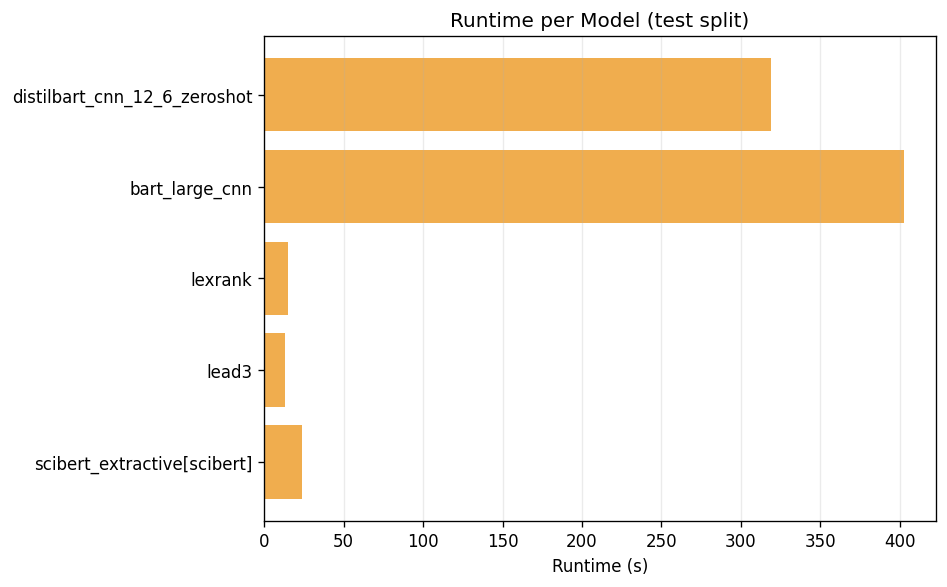

In [22]:
# Runtime bar
plt.figure(figsize=(8, 5))
plt.barh(df_all["model"], df_all["seconds"], color="#f0ad4e")
plt.xlabel("Runtime (s)"); plt.title("Runtime per Model (test split)")
plt.gca().invert_yaxis(); plt.grid(axis="x", alpha=0.25); plt.tight_layout()
plt.savefig(os.path.join(EVAL_DIR, "runtime_bar.png"), dpi=150)
plt.show()


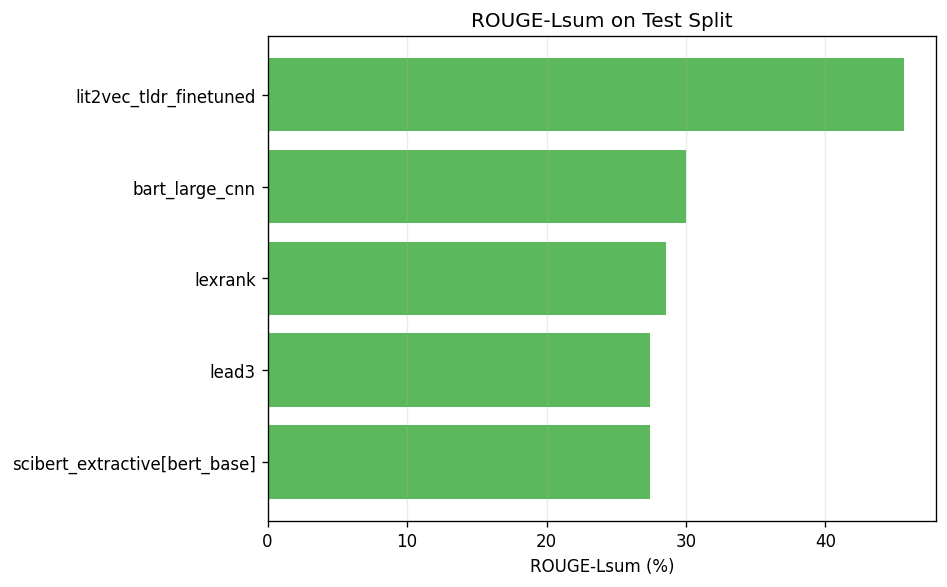

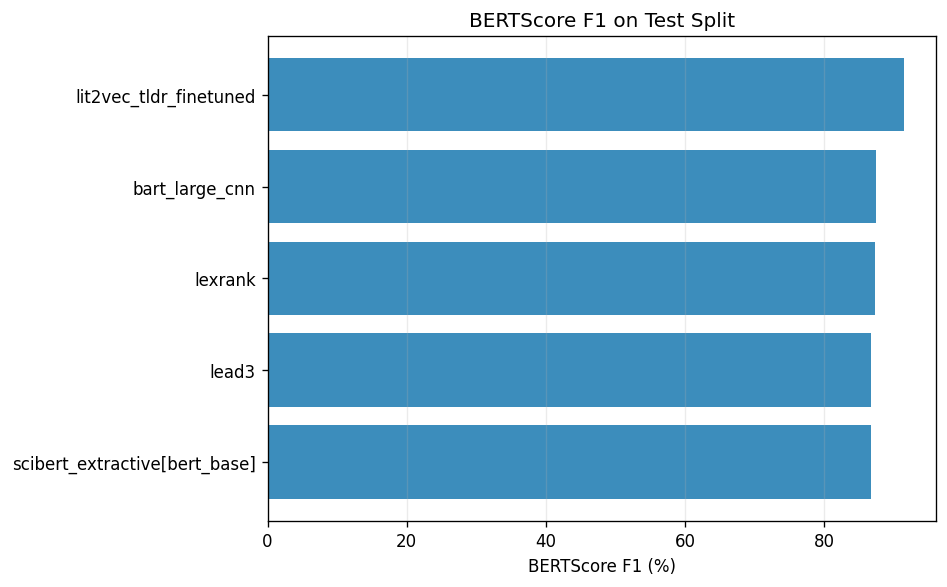

In [ ]:

# %%
# ## 10. Plots: ROUGE bar & BERTScore bar

# ROUGE (Lsum) bar
plt.figure(figsize=(8, 5))
plt.barh(df_all["model"], df_all["rougeLsum"], color="#5cb85c")
plt.xlabel("ROUGE-Lsum (%)"); plt.title("ROUGE-Lsum on Test Split")
plt.gca().invert_yaxis(); plt.grid(axis="x", alpha=0.25); plt.tight_layout()
plt.savefig(os.path.join(EVAL_DIR, "rougeLsum_bar.png"), dpi=150)
plt.show()

# BERTScore F1 bar
plt.figure(figsize=(8, 5))
plt.barh(df_all["model"], df_all["bertscore_f1"], color="#3c8dbc")
plt.xlabel("BERTScore F1 (%)"); plt.title("BERTScore F1 on Test Split")
plt.gca().invert_yaxis(); plt.grid(axis="x", alpha=0.25); plt.tight_layout()
plt.savefig(os.path.join(EVAL_DIR, "bertscoreF1_bar.png"), dpi=150)
plt.show()


In [25]:

# %%
# ## 11. Inspect a few sample predictions from fine-tuned model

sample_n = min(3, len(finetuned_preds))
sample_df = pd.DataFrame({
    "abstract": test_ds["abstract"][:sample_n],
    "reference": test_ds["summary"][:sample_n],
    "prediction": postprocess_text(finetuned_preds[:sample_n], finetuned_refs[:sample_n])[0]
})
for idx, row in sample_df.iterrows():
    print("="*90)
    print(f"EXAMPLE {idx+1}")
    print("\nABSTRACT:\n", row["abstract"])
    print("\nREFERENCE SUMMARY:\n", row["reference"])
    print("\nPREDICTED SUMMARY:\n", row["prediction"])


EXAMPLE 1

ABSTRACT:
 Ultraviolet B (UVB; 290~320nm) irradiation-induced lipid peroxidation induces inflammatory responses that lead to skin wrinkle formation and epidermal thickening. Peroxisome proliferator-activated receptor (PPAR) α/γ dual agonists have the potential to be used as anti-wrinkle agents because they inhibit inflammatory response and lipid peroxidation. In this study, we evaluated the function of 2-bromo-4-(5-chloro-benzo[d]thiazol-2-yl) phenol (MHY 966), a novel synthetic PPAR α/γ dual agonist, and investigated its anti-inflammatory and anti-lipid peroxidation effects. The action of MHY 966 as a PPAR α/γ dual agonist was also determined in vitro by reporter gene assay. Additionally, 8-week-old melanin-possessing hairless mice 2 (HRM2) were exposed to 150 mJ/cm2 UVB every other day for 17 days and MHY 966 was simultaneously pre-treated every day for 17 days to investigate the molecular mechanisms involved. MHY 966 was found to stimulate the transcriptional activities o

In [26]:
# %%
# ## 12. Save a JSON snapshot of consolidated metrics (resilient)

import os, json, math
import pandas as pd

def _maybe_read(path):
    return pd.read_csv(path) if os.path.exists(path) else None

cols = ["model","rouge1","rouge2","rougeL","rougeLsum",
        "bertscore_precision","bertscore_recall","bertscore_f1"]

# 1) Gather sources: prefer in-memory, fall back to saved CSVs
dfs = []

if "df_all" in locals():
    dfs.append(df_all)
else:
    if "df_abstractive" in locals():
        dfs.append(df_abstractive)
    else:
        dfa = _maybe_read(os.path.join(EVAL_DIR, "abstractive_benchmarks.csv"))
        if dfa is not None:
            dfs.append(dfa)

    if "df_extractive" in locals():
        dfs.append(df_extractive)
    else:
        dfe = _maybe_read(os.path.join(EVAL_DIR, "extractive_benchmarks.csv"))
        if dfe is not None:
            dfs.append(dfe)

if not dfs:
    raise RuntimeError(
        "No results available to snapshot. Run Sections 7 (abstractive) and 8 (extractive), "
        "or ensure their CSVs exist in EVAL_DIR."
    )

# 2) Build df_all with consistent metric columns
df_all = pd.concat(dfs, ignore_index=True)
for c in cols:
    if c not in df_all.columns:
        df_all[c] = math.nan
df_all = df_all[cols].sort_values(by=["bertscore_f1","rougeL"], ascending=False)

# 3) Save consolidated CSV + JSON snapshot
csv_path = os.path.join(EVAL_DIR, "benchmark_all_models.csv")
json_path = os.path.join(EVAL_DIR, "benchmark_snapshot.json")
df_all.to_csv(csv_path, index=False)
with open(json_path, "w") as f:
    json.dump(df_all.to_dict(orient="records"), f, indent=2)

print("✅ Saved:")
print("  •", csv_path)
print("  •", json_path)


✅ Saved:
  • ./evaluation/benchmark_all_models.csv
  • ./evaluation/benchmark_snapshot.json
